# Project 1: VaR and ES -- Estimation, Backtesting, and Model Comparison

**Names of all group members:**
- Firstname Lastname (email@example.com)
- Firstname Lastname (email@example.com)

---

## 0) Setup

Creates necessary folders, sets parameters, and fixes the random seed. Keep this seed fixed; the whole run must be reproducible from it.

In [35]:
# If a package import fails, install it in your environment, e.g.:
# %pip install arch statsmodels

import os
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path.cwd()
DATA_FILE = PROJECT_DIR / "QRM_2026_Project_prices.csv"   # provided with the project; do not re-download
OUT_DIR = PROJECT_DIR / "output"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Parameters
TICKERS = ["AAPL", "META", "JPM"]   # every question is run separately on each stock
WINDOW = 504                        # estimation window of every model, in trading days (Questions 2-5)
EVAL_START = 504                    # Questions 3-5: forecast days are all days after the first 504
REFIT = 21                          # Questions 4-5: re-estimate every this many trading days
ALPHAS = [0.975, 0.99]              # confidence levels used throughout Questions 2-5
DEEP_ALPHA = 0.999                  # Question 6: the extreme level EVT is asked for
M_SIM = 10_000                      # Questions 3(c), 4(d): Acerbi-Szekely simulated samples
LB_LAGS = 10                        # Ljung-Box H in Questions 1 and 4
NW_LAGS = 10                        # Newey-West truncation lag of the Diebold-Mariano test
SEED = 0                            # fix this, state it in the report, do not change it later

rng = np.random.default_rng(SEED)
print("Project dir:", PROJECT_DIR)


Project dir: /Users/imanelahrichi/Documents/EPFL/Master/qrm/Project-QRM


## 1) Data

The prices were downloaded once with `yfinance` (adjusted closes, 2 January 2013 to 30 June 2026,
downloaded on 28 October 2026) and are provided as `QRM_2026_Project_prices.csv`. Read this file;
do not download the data again, since Yahoo revises adjusted prices back in time.

In [36]:
price_df = pd.read_csv(DATA_FILE, index_col=0, parse_dates=True)[TICKERS]
print(price_df.head())
print(price_df.shape, price_df.index[0].date(), "to", price_df.index[-1].date())   # (3393, 3)

                 AAPL       META        JPM
Date                                       
2013-01-02  16.567112  27.734369  31.045462
2013-01-03  16.357998  27.506550  30.982899
2013-01-04  15.902353  28.487160  31.532061
2013-01-07  15.808805  29.140898  31.566807
2013-01-08  15.851354  28.784311  31.629383
(3393, 3) 2013-01-02 to 2026-06-30


## 2) Log-returns and losses

Construct $R_t=\log(P_t/P_{t-1})$ for each ticker. The log-loss used everywhere in this project is
$L_t=-R_t$. Every question is run separately on each of the three columns; there is no portfolio.

In [37]:
returns = np.log(price_df / price_df.shift(1)).dropna()
losses = -returns

print(returns.shape, returns.index[0].date(), "to", returns.index[-1].date())   # (3392, 3)
returns.head()

(3392, 3) 2013-01-03 to 2026-06-30


,AAPL,META,JPM
Date,,,
2013-01-03,-0.012703,-0.008248,-0.002017
2013-01-04,-0.028250,0.035029,0.017569
2013-01-07,-0.005900,0.022689,0.001101
2013-01-08,0.002688,-0.012312,0.001980
2013-01-09,-0.015752,0.051311,-0.000660


## Question 1 -- Stylized facts

For each stock: (a) plot the return series; (b) ACF of returns and of squared returns, and the
Ljung-Box test with $H$ = `LB_LAGS` on both (`statsmodels.stats.diagnostic.acorr_ljungbox`);
(c) QQ-plot and Jarque-Bera.

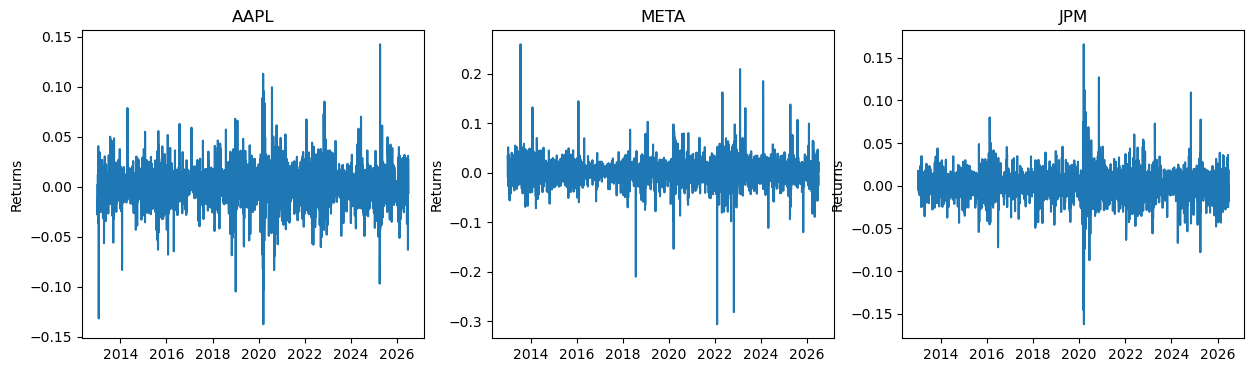

In [38]:
tickers = TICKERS                       # name used in Questions 1 and 4

# Question 1

plt.figure(figsize=(15,4))

plt.subplot(1,3,1)
plt.plot(returns["AAPL"])
plt.ylabel("Returns")
plt.title("AAPL")

plt.subplot(1,3,2)
plt.plot(returns["META"])
plt.ylabel("Returns")
plt.title("META")

plt.subplot(1,3,3)
plt.plot(returns["JPM"])
plt.ylabel("Returns")
plt.title("JPM")

plt.show()

Text(0, 0.5, 'ACF')

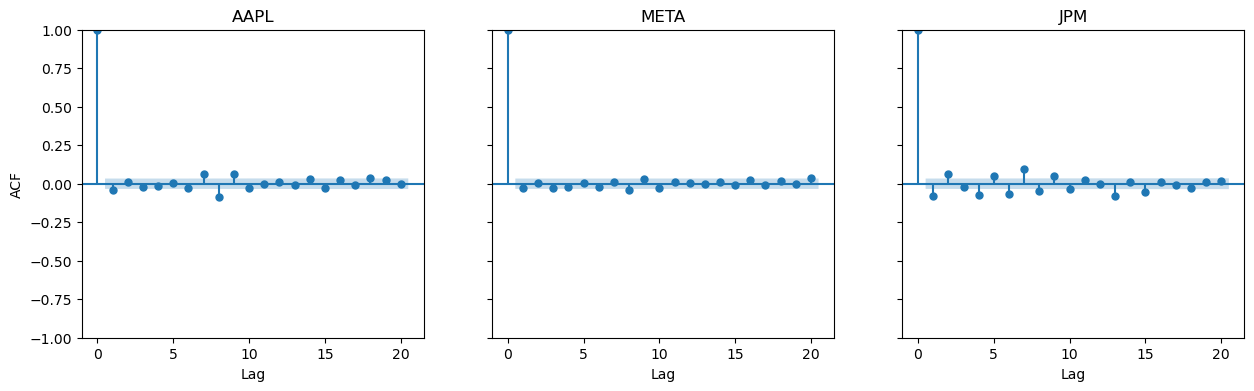

In [39]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf

acf_AAPL = acf(returns["AAPL"].dropna(), nlags=20)
acf_META = acf(returns["META"].dropna(), nlags=20)
acf_JPM = acf(returns["JPM"].dropna(), nlags=20)


fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

tickers = ["AAPL", "META", "JPM"]
for ax, ticker in zip(axes, tickers):
    plot_acf(returns[ticker].dropna(), lags=20, alpha=0.05, ax=ax)
    ax.set_title(ticker)
    ax.set_xlabel("Lag")


axes[0].set_ylabel("ACF")


Text(0, 0.5, 'ACF')

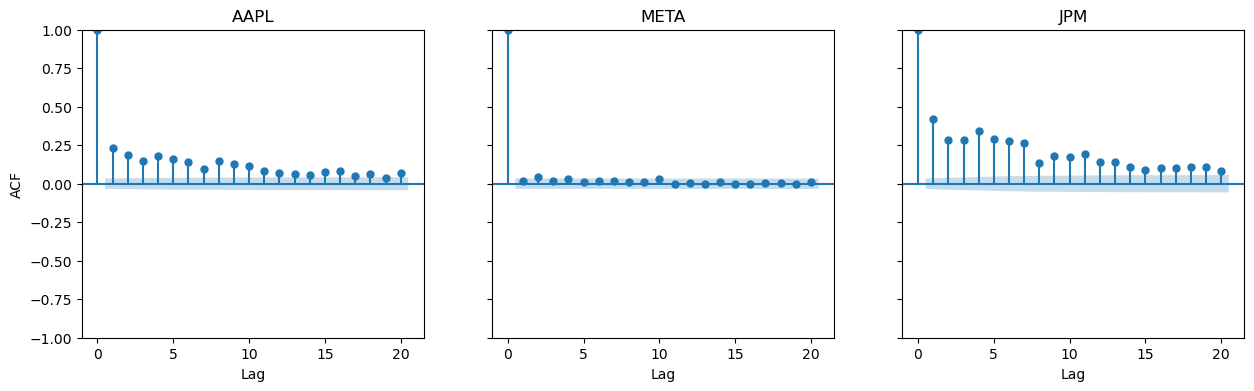

In [40]:
acf_AAPL2 = acf((returns["AAPL"].dropna())**2, nlags=20)
acf_META2 = acf((returns["META"].dropna())**2, nlags=20)
acf_JPM2 = acf((returns["JPM"].dropna())**2, nlags=20)


fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

tickers = ["AAPL", "META", "JPM"]
for ax, ticker in zip(axes, tickers):
    plot_acf((returns[ticker]**2).dropna(), lags=20, alpha=0.05, ax=ax)
    ax.set_title(ticker)
    ax.set_xlabel("Lag")


axes[0].set_ylabel("ACF")


In [41]:
from statsmodels.stats.diagnostic import acorr_ljungbox

results_lb = []
for ticker in tickers:
    lb_returns = acorr_ljungbox(returns[ticker], lags=[LB_LAGS], return_df=True)
    lb_squared = acorr_ljungbox(returns[ticker]**2, lags=[LB_LAGS], return_df=True)

    results_lb.append({"Ticker": ticker,"p_returns": lb_returns["lb_pvalue"].iloc[0],"p_squared": lb_squared["lb_pvalue"].iloc[0]})

results_lb = pd.DataFrame(results_lb)
print(results_lb)

  Ticker     p_returns      p_squared
0   AAPL  5.209219e-10  5.179304e-176
1   META  3.352590e-02   3.904220e-02
2    JPM  6.791373e-22   0.000000e+00


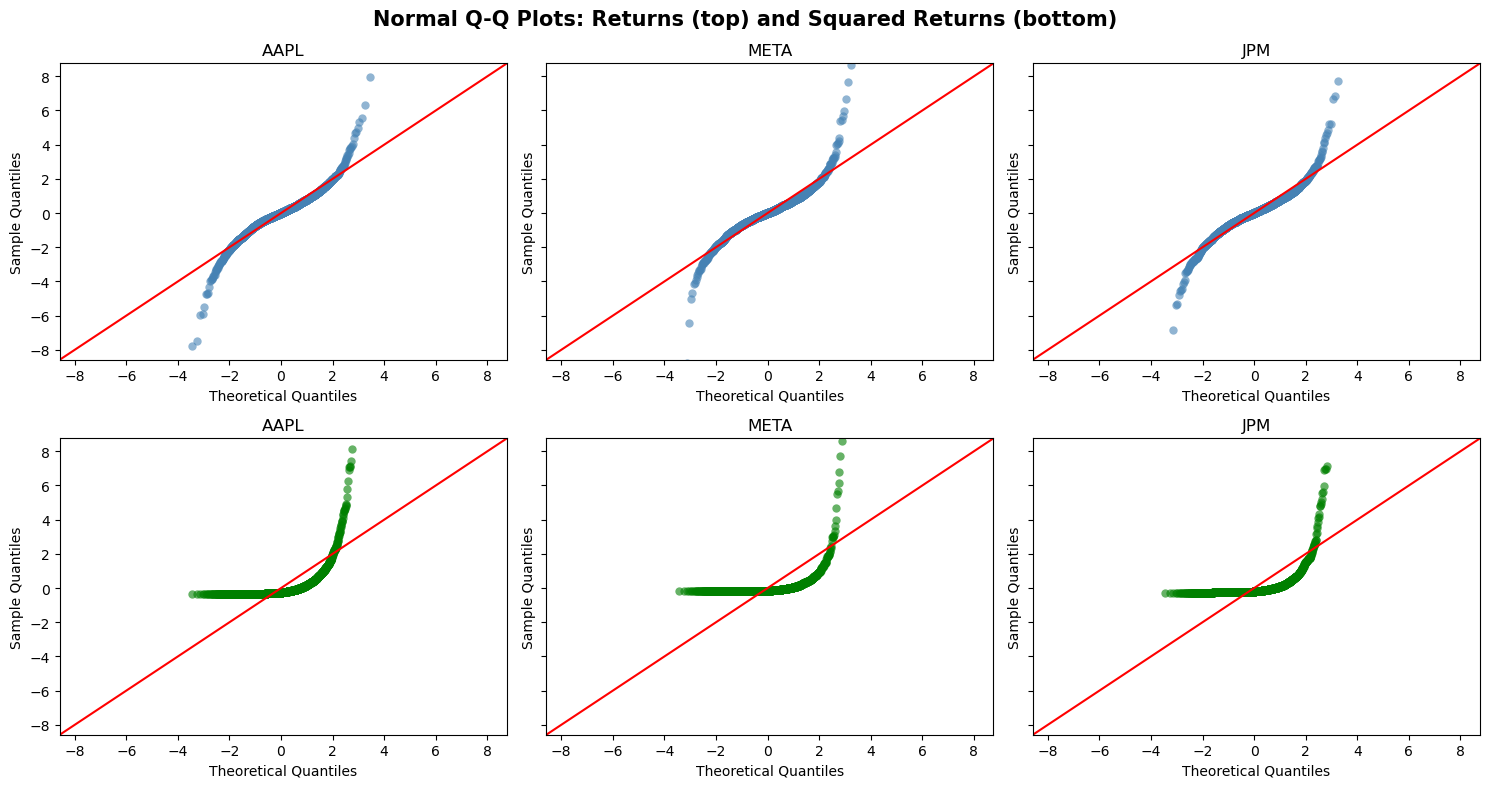

In [42]:
import statsmodels.api as sm


fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)

for i, ticker in enumerate(tickers):
    sm.qqplot(returns[ticker], fit=True, line="45", ax=axes[0,i], markerfacecolor="steelblue", markeredgecolor="none",alpha=0.6)
    sm.qqplot(returns[ticker]**2, fit=True, line="45", ax=axes[1,i], markerfacecolor="green", markeredgecolor="none",alpha=0.6)

    axes[0, i].set_title(ticker)
    axes[1, i].set_title(ticker)

fig.suptitle("Normal Q-Q Plots: Returns (top) and Squared Returns (bottom)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

In [43]:
from scipy.stats import jarque_bera

jb_values = []

for ticker in tickers: 
    stat, pvalue = jarque_bera(returns[ticker].dropna())
    jb_values.append({"Ticker": ticker,"stat": stat,"pvalue": pvalue})

jb_values = pd.DataFrame(jb_values)
print(jb_values)

  Ticker          stat  pvalue
0   AAPL   6590.613996     0.0
1   META  84216.050984     0.0
2    JPM  23655.819050     0.0


## Question 2 -- Single-window VaR and ES estimates

For each stock, use the first `WINDOW` losses as the single estimation window for (a)-(d).

AAPL: Gaussian mu=-0.00075, sd=0.01603 | Student-t nu=4.13, mu=-0.00106, scale=0.01113
META: Gaussian mu=-0.00204, sd=0.02512 | Student-t nu=4.68, mu=-0.00131, scale=0.01780
JPM: Gaussian mu=-0.00077, sd=0.01161 | Student-t nu=6.48, mu=-0.00096, scale=0.00974

alpha = 0.975, VaR (%):
stock      AAPL   JPM  META
method                     
Gaussian   3.07  2.20  4.72
HS         2.90  2.38  4.23
Student-t  2.95  2.24  4.54
alpha = 0.975, ES (%):
stock      AAPL   JPM  META
method                     
Gaussian   3.67  2.64  5.67
HS         4.97  2.92  5.60
Student-t  4.25  2.99  6.35

alpha = 0.99, VaR (%):
stock      AAPL   JPM  META
method                     
Gaussian   3.65  2.62  5.64
HS         3.89  2.78  5.35
Student-t  3.99  2.89  6.03
alpha = 0.99, ES (%):
stock      AAPL   JPM  META
method                     
Gaussian   4.20  3.02  6.49
HS         7.39  3.54  6.53
Student-t  5.56  3.69  8.14


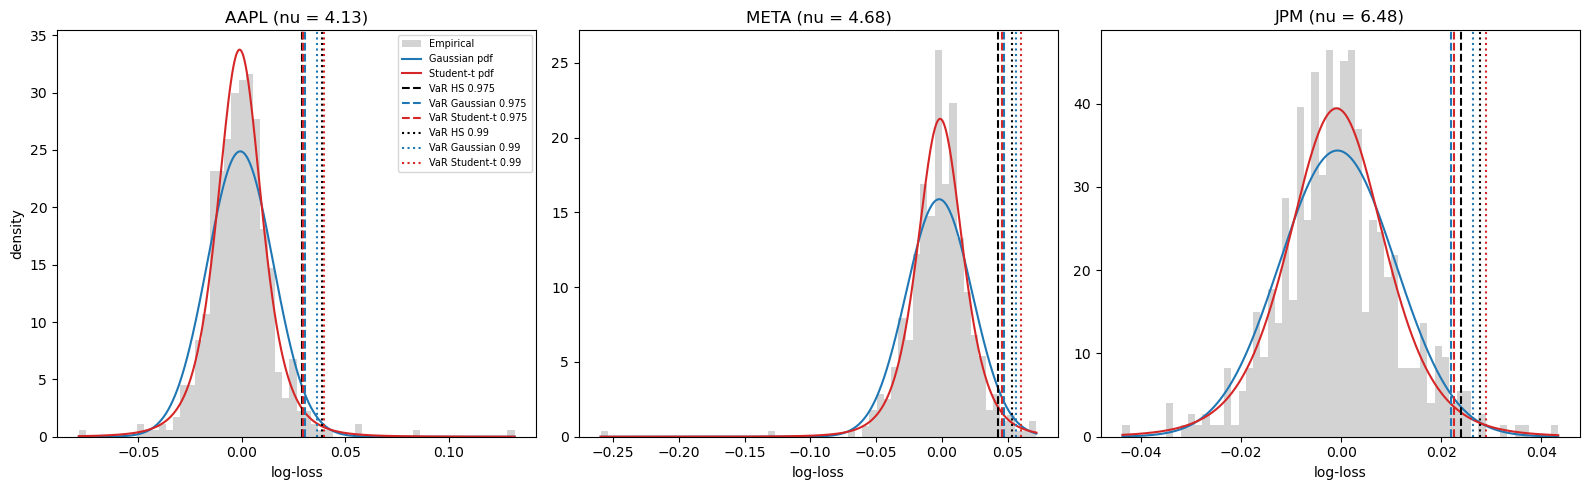

In [44]:
# Question 2
window_loss = losses.iloc[:WINDOW]          # first 504 losses, one column per stock


# ============ 1. Functions: each returns (VaR, ES) ============

def hs_var_es(x, alpha):
    """(a) Historical simulation."""
    L = np.sort(x)[::-1]                    # sort losses from largest to smallest
    W = len(L)                              # 504
    k = int(np.floor(W * (1 - alpha)))      # number of losses strictly beyond the VaR
    var = L[k]                              # the (k+1)-th largest loss (Python starts counting at 0)
    es = (L[:k].sum() + (W * (1 - alpha) - k) * L[k]) / (W * (1 - alpha))
    return var, es


def gauss_var_es(mu, sigma, alpha):
    """(b) VaR and ES of a normal distribution N(mu, sigma^2)."""
    z = stats.norm.ppf(alpha)               # alpha-quantile of N(0,1)
    var = mu + sigma * z
    es = mu + sigma * stats.norm.pdf(z) / (1 - alpha)
    return var, es


def t_fit(x):
    """(c) Fit a Student-t (nu, mu, s) by maximum likelihood.
    t.fit can get stuck at a local optimum, so try 4 starting values of nu
    and keep the fit with the highest log-likelihood."""
    best_fit, best_loglik = None, -np.inf
    for nu_start in [3, 5, 10, 30]:
        fit = stats.t.fit(x, nu_start)                  # (nu, mu, s)
        loglik = stats.t.logpdf(x, *fit).sum()          # how well this fit explains the data
        if loglik > best_loglik:
            best_fit, best_loglik = fit, loglik
    return best_fit


def t_var_es(nu, mu, s, alpha):
    """(c) VaR and ES of a Student-t with location mu and scale s."""
    q = stats.t.ppf(alpha, nu)              # alpha-quantile of the standard t
    var = mu + s * q
    es = mu + s * stats.t.pdf(q, nu) / (1 - alpha) * (nu + q**2) / (nu - 1)
    return var, es


# ============ 2. Apply the three methods to each stock ============

rows = []                                   # one row per (stock, alpha, method)
fits = {}                                   # fitted parameters, kept for the plot

for tic in TICKERS:
    x = window_loss[tic].values

    mu_g, sd_g = x.mean(), x.std(ddof=1)    # Gaussian: sample mean and std
    nu, mu_t, s_t = t_fit(x)                # Student-t: maximum likelihood
    fits[tic] = (mu_g, sd_g, nu, mu_t, s_t)
    print(f"{tic}: Gaussian mu={mu_g:.5f}, sd={sd_g:.5f} | "
          f"Student-t nu={nu:.2f}, mu={mu_t:.5f}, scale={s_t:.5f}")

    for a in ALPHAS:
        var, es = hs_var_es(x, a)
        rows.append([tic, a, "HS", var, es])
        var, es = gauss_var_es(mu_g, sd_g, a)
        rows.append([tic, a, "Gaussian", var, es])
        var, es = t_var_es(nu, mu_t, s_t, a)
        rows.append([tic, a, "Student-t", var, es])

results = pd.DataFrame(rows, columns=["stock", "alpha", "method", "VaR", "ES"])

# Print one small table per level: rows = method, columns = stock, in %
for a in ALPHAS:
    sub = results[results.alpha == a]
    print(f"\nalpha = {a}, VaR (%):")
    print((100 * sub.pivot(index="method", columns="stock", values="VaR")).round(2))
    print(f"alpha = {a}, ES (%):")
    print((100 * sub.pivot(index="method", columns="stock", values="ES")).round(2))

results.to_csv(OUT_DIR / "q2_var_es.csv", index=False)


# ============ 3. (d) Plot: histogram + two densities + VaR lines ============

colors = {"HS": "black", "Gaussian": "tab:blue", "Student-t": "tab:red"}
styles = {0.975: "--", 0.99: ":"}           # dashed = 97.5%, dotted = 99%

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, tic in zip(axes, TICKERS):
    x = window_loss[tic].values
    mu_g, sd_g, nu, mu_t, s_t = fits[tic]
    grid = np.linspace(x.min(), x.max(), 1000)          # x-values where we draw the pdfs

    ax.hist(x, bins=60, density=True, color="lightgray", label="Empirical")
    ax.plot(grid, stats.norm.pdf(grid, mu_g, sd_g), color="tab:blue", label="Gaussian pdf")
    ax.plot(grid, stats.t.pdf(grid, nu, mu_t, s_t), color="tab:red", label="Student-t pdf")

    # one vertical line per VaR estimate of this stock
    r = results[results.stock == tic]
    for method, a, var in zip(r.method, r.alpha, r.VaR):
        ax.axvline(var, color=colors[method], ls=styles[a], label=f"VaR {method} {a}")

    ax.set_title(f"{tic} (nu = {nu:.2f})")
    ax.set_xlabel("log-loss")

axes[0].set_ylabel("density")
axes[0].legend(fontsize=7)                  # same legend for all three panels, show it once
plt.tight_layout()
plt.savefig(OUT_DIR / "q2_densities.png", dpi=200)
plt.show()

## Question 3 -- Backtesting

Forecast every day of the evaluation period `losses.iloc[EVAL_START:]`, each model estimated on the
`WINDOW` days before the forecast day. Historical simulation, Gaussian and Student-$t$ are recomputed
every day. Write the Kupiec, Christoffersen, Acerbi-Szekely, Fissler-Ziegel, pinball-loss and
Diebold-Mariano functions yourself, from the course slides (Kupiec, Christoffersen) and Appendix A of
the project statement (the others); they are
reused unchanged in Questions 4 and 5.

The combined VaR backtest table collects the VaR backtests of Questions 3-5: append one row per
stock, method and level to `backtest_rows` as you go. The ES backtest table ($\alpha=0.975$) collects
the Acerbi-Szekely and Fissler-Ziegel results of Questions 3 and 4 in `es_rows`.

In [45]:
# Question 3
eval_loss = losses.iloc[EVAL_START:]        # one column per stock, 2888 forecast days
backtest_rows = []                          # dicts: stock, method, alpha, x, expected, hit, p_uc, p_ind, p_cc, pinball_bp
es_rows = []                                # dicts: stock, method, Z, p_Z, FZ


In [46]:
# Q3 : VaR / ES of the 3 methods
alphas = np.array(ALPHAS)
idx = np.ceil(WINDOW * alphas).astype(int) - 1
k = WINDOW - idx - 1


def hs_risk(window):
    Ls = np.sort(window)
    var = Ls[idx]
    ES = np.array([(Ls[i + 1:].sum() + (WINDOW * (1 - a) - j) * Ls[i]) / (WINDOW * (1 - a))
                   for i, j, a in zip(idx, k, alphas)])
    return var, ES


def normal_risk(window):
    mu = np.mean(window)
    sd = np.std(window, ddof=1)
    z = stats.norm.ppf(alphas)
    var = mu + sd * z
    ES = mu + sd * stats.norm.pdf(z) / (1 - alphas)
    return var, ES


def student_risk(df, loc, scale):
    q = stats.t.ppf(alphas, df)
    var = loc + scale * q
    ES = loc + scale * stats.t.pdf(q, df) / (1 - alphas) * (df + q**2) / (df - 1)
    return var, ES


methods = ["HS", "Gaussian", "Student-t"]
VaR_fc = {}
ES_fc = {}
nu_hist = {}

for tk in TICKERS:
    L = losses[tk].values
    for m in methods:
        VaR_fc[(tk, m)] = []
        ES_fc[(tk, m)] = []
    nu_hist[tk] = []

    for t in range(EVAL_START, len(L)):
        window = L[t - WINDOW:t]

        # t fit, also from yesterday's params (local optimum)
        df, loc, scale = stats.t.fit(window)
        if t > EVAL_START:
            df2, loc2, scale2 = stats.t.fit(window, df_old, loc=loc_old, scale=scale_old)
            if stats.t.logpdf(window, df2, loc2, scale2).sum() > stats.t.logpdf(window, df, loc, scale).sum():
                df, loc, scale = df2, loc2, scale2
        df_old, loc_old, scale_old = df, loc, scale
        nu_hist[tk].append(df)

        for m, (var, ES) in zip(methods, [hs_risk(window), normal_risk(window), student_risk(df, loc, scale)]):
            VaR_fc[(tk, m)].append(var)
            ES_fc[(tk, m)].append(ES)

for key in VaR_fc:
    VaR_fc[key] = pd.DataFrame(VaR_fc[key], index=eval_loss.index, columns=ALPHAS)
    ES_fc[key] = pd.DataFrame(ES_fc[key], index=eval_loss.index, columns=ALPHAS)

# first day should match Q2
for tk in TICKERS:
    print(tk, [round(100 * VaR_fc[(tk, m)][0.99].iloc[0], 3) for m in methods])

KeyboardInterrupt: 

In [ ]:
# Q3 : backtest
def backtest_var(VaR, L_test, alpha):
    I = (L_test > VaR).astype(int).values
    n = len(I)
    x = I.sum()
    po = 1 - alpha
    p = x / n

    # Kupiec
    LRuc = 2 * (x * np.log(p / po) + (n - x) * np.log((1 - p) / (1 - po)))

    # Christoffersen
    prev, curr = I[:-1], I[1:]
    n00 = np.sum((prev == 0) & (curr == 0))
    n01 = np.sum((prev == 0) & (curr == 1))
    n10 = np.sum((prev == 1) & (curr == 0))
    n11 = np.sum((prev == 1) & (curr == 1))

    p01 = n01 / (n00 + n01)
    p11 = n11 / (n10 + n11)
    p_all = (n01 + n11) / (n00 + n01 + n10 + n11)

    l0 = (n01 + n11) * np.log(p_all) + (n00 + n10) * np.log(1 - p_all)
    l1 = n01 * np.log(p01) + n00 * np.log(1 - p01)
    if n11 > 0:
        l1 += n11 * np.log(p11)
    if n10 > 0:
        l1 += n10 * np.log(1 - p11)

    LRind = -2 * (l0 - l1)
    LRcc = LRuc + LRind

    # pinball
    pin = ((L_test <= VaR) - alpha) * (VaR - L_test)

    return {"x": x,
            "expected": n * po,
            "hit": p,
            "p_uc": 1 - stats.chi2.cdf(LRuc, 1),
            "p_ind": 1 - stats.chi2.cdf(LRind, 1),
            "p_cc": 1 - stats.chi2.cdf(LRcc, 2),
            "pinball_bp": 1e4 * pin.mean()}

In [ ]:
# Q3 (a)
for (tk, m), VaR in VaR_fc.items():
    for alpha in ALPHAS:
        res = backtest_var(VaR[alpha], eval_loss[tk], alpha)
        backtest_rows.append({"stock": tk, "method": m, "alpha": alpha, **res})

table_q3 = pd.DataFrame(backtest_rows).set_index(["alpha", "stock", "method"]).sort_index()
table_q3.to_csv(OUT_DIR / "q3_var_backtest.csv")

for alpha in ALPHAS:
    print("alpha =", alpha)
    display(table_q3.loc[alpha].round(3))

alpha = 0.975


x  expected    hit   p_uc  p_ind   p_cc  pinball_bp
stock method                                                          
AAPL  Gaussian   105      72.2  0.036  0.000  0.000  0.000      13.748
      HS          86      72.2  0.030  0.110  0.004  0.005      13.601
      Student-t  103      72.2  0.036  0.001  0.000  0.000      13.716
JPM   Gaussian    95      72.2  0.033  0.009  0.000  0.000      13.207
      HS          83      72.2  0.029  0.208  0.000  0.000      13.023
      Student-t   92      72.2  0.032  0.023  0.000  0.000      13.303
META  Gaussian    78      72.2  0.027  0.495  0.000  0.001      18.321
      HS          75      72.2  0.026  0.740  0.016  0.051      18.262
      Student-t   89      72.2  0.031  0.053  0.000  0.000      18.285

alpha = 0.99


x  expected    hit   p_uc  p_ind   p_cc  pinball_bp
stock method                                                         
AAPL  Gaussian   62     28.88  0.021  0.000  0.012  0.000       7.658
      HS         41     28.88  0.014  0.033  0.138  0.034       7.244
      Student-t  41     28.88  0.014  0.033  0.138  0.034       7.211
JPM   Gaussian   64     28.88  0.022  0.000  0.000  0.000       7.581
      HS         42     28.88  0.015  0.022  0.000  0.000       7.216
      Student-t  47     28.88  0.016  0.002  0.000  0.000       7.353
META  Gaussian   52     28.88  0.018  0.000  0.002  0.000      10.672
      HS         40     28.88  0.014  0.049  0.125  0.045      10.372
      Student-t  38     28.88  0.013  0.104  0.102  0.070      10.501

In [ ]:
# Q3 (b)
verdict = table_q3[["x", "expected", "p_uc", "p_ind", "p_cc"]].copy()
verdict["fail_uc"] = verdict["p_uc"] < 0.05
verdict["fail_ind"] = verdict["p_ind"] < 0.05
verdict["fail_cc"] = verdict["p_cc"] < 0.05
display(verdict.round(3))

# Kupiec and cc disagree
display(verdict[verdict["fail_uc"] != verdict["fail_cc"]].round(3))

x  expected   p_uc  p_ind   p_cc  fail_uc  fail_ind  \
alpha stock method                                                             
0.975 AAPL  Gaussian   105     72.20  0.000  0.000  0.000     True      True   
            HS          86     72.20  0.110  0.004  0.005    False      True   
            Student-t  103     72.20  0.001  0.000  0.000     True      True   
      JPM   Gaussian    95     72.20  0.009  0.000  0.000     True      True   
            HS          83     72.20  0.208  0.000  0.000    False      True   
            Student-t   92     72.20  0.023  0.000  0.000     True      True   
      META  Gaussian    78     72.20  0.495  0.000  0.001    False      True   
            HS          75     72.20  0.740  0.016  0.051    False      True   
            Student-t   89     72.20  0.053  0.000  0.000    False      True   
0.990 AAPL  Gaussian    62     28.88  0.000  0.012  0.000     True      True   
            HS          41     28.88  0.033  0.138  0.034     True     False   
            Student-t   41     28.88  0.033  0.138  0.034     True     False   
      JPM   Gaussian    64     28.88  0.000  0.000  0.000     True      True   
            HS          42     28.88  0.022  0.000  0.000     True      True   
            Student-t   47     28.88  0.002  0.000  0.000     True      True   
      META  Gaussian    52     28.88  0.000  0.002  0.000     True      True   
            HS          40     28.88  0.049  0.125  0.045     True     False   
            Student-t   38     28.88  0.104  0.102  0.070    False     False   

                       fail_cc  
alpha stock method              
0.975 AAPL  Gaussian      True  
            HS            True  
            Student-t     True  
      JPM   Gaussian      True  
            HS            True  
            Student-t     True  
      META  Gaussian      True  
            HS           False  
            Student-t     True  
0.990 AAPL  Gaussian      True  
            HS            True  
            Student-t     True  
      JPM   Gaussian      True  
            HS            True  
            Student-t     True  
      META  Gaussian      True  
            HS            True  
            Student-t    False

x  expected   p_uc  p_ind   p_cc  fail_uc  fail_ind  \
alpha stock method                                                            
0.975 AAPL  HS         86      72.2  0.110  0.004  0.005    False      True   
      JPM   HS         83      72.2  0.208  0.000  0.000    False      True   
      META  Gaussian   78      72.2  0.495  0.000  0.001    False      True   
            Student-t  89      72.2  0.053  0.000  0.000    False      True   

                       fail_cc  
alpha stock method              
0.975 AAPL  HS            True  
      JPM   HS            True  
      META  Gaussian      True  
            Student-t     True

## Question 4 -- AR-GARCH conditional VaR and ES

(a) Mean model, full sample: fit AR($p$), $p=0,\dots,3$, with constant variance on the same
observations, e.g. `ARX(y, lags=p, hold_back=3)` from `arch.univariate`; pick $p$ by BIC (also report
AIC); Ljung-Box on the residuals (`model_df=p`) and on their squares.
(b) Fit `arch_model(y, mean="AR", lags=p, vol="GARCH", p=1, q=1, dist=..., hold_back=3)` on the full
sample with `dist="normal"` and `dist="t"` (use `mean="Constant"` if $p=0$); Ljung-Box on the
standardized residuals of the Gaussian fit (`model_df=p`) and their squares (`model_df=2`).
(c) Re-estimate both inside the rolling scheme every `REFIT` days with the same $p$. Between refits,
keep the parameters fixed but advance $\hat\mu_t$ and $\hat\sigma_t$ daily with the realized
returns (for example with `arch_model(...).fix(params)` on the data up to the forecast day). Fit on
returns in percent (`100 * R`) to avoid `arch` convergence warnings, and convert the forecasts back.
(d) Backtest both and add them to the two tables.

In [ ]:
# Names used by the Question 4 cells
tickers = TICKERS
from scipy.stats import norm

In [ ]:
# Question 4
# Part a) i)
from arch.univariate import ARX

fits_tickers = []
residuals = {}

for ticker in tickers:
    fits = []
    for p in [0, 1, 2, 3]:
        fit = ARX(100*returns[ticker], lags=p, hold_back=3).fit(disp="off")
        fits_tickers.append({"ticker": ticker, "p": p, "BIC": fit.bic, "AIC": fit.aic, "coefficients": fit.params.to_dict()})
        residuals[(ticker, p)] = fit.resid

fits_tickers = pd.DataFrame(fits_tickers)
print(fits_tickers[["ticker", "p", "BIC", "AIC"]].round(2).to_string(index=False))

p_bic_aic = []
for ticker in tickers:
    df = fits_tickers[fits_tickers["ticker"] == ticker]
    m_bic = df["BIC"].min()
    m_aic = df["AIC"].min()
    p_bic = df[df["BIC"] == m_bic]["p"].iloc[0]
    p_aic = df[df["AIC"] == m_aic]["p"].iloc[0]
    p_bic_aic.append({"ticker":ticker , "best_p_bic":p_bic, "best_p_aic":p_aic})

p_bic_aic = pd.DataFrame(p_bic_aic)
p_bic_aic

ticker  p      BIC      AIC
  AAPL  0 13536.93 13524.67
  AAPL  1 13539.01 13520.62
  AAPL  2 13546.78 13522.27
  AAPL  3 13553.52 13522.88
  META  0 15591.56 15579.30
  META  1 15597.07 15578.69
  META  2 15605.18 15580.67
  META  3 15610.97 15580.33
   JPM  0 12953.07 12940.81
   JPM  1 12941.04 12922.65
   JPM  2 12937.97 12913.46
   JPM  3 12945.67 12915.03


,ticker,best_p_bic,best_p_aic
0,AAPL,0,1
1,META,0,1
2,JPM,2,2


In [ ]:
# Part a) ii) 

rows = []
for ticker in tickers:
    p = int(p_bic_aic.set_index("ticker").loc[ticker, "best_p_bic"])
    fit = ARX(100*returns[ticker], lags=p if p > 0 else None, hold_back=3).fit(disp="off")

    params, se, cov = fit.params, fit.std_err, fit.param_cov
    c = params.iloc[0]                     
    phi = params.iloc[1:1+p].to_numpy()     
    s = 1 - phi.sum()
    
    mu = c / s
    grad = np.r_[1 / s, np.full(p, c / s**2)]           
    V = cov.iloc[:1+p, :1+p].to_numpy()
    se_mu = np.sqrt(grad @ V @ grad)

    row = {"ticker": ticker, "p": p,
           "Const (c)": c, "se(c)": se.iloc[0],
           "mu": mu, "se(mu)": se_mu}
    for i in range(p):
        row[f"phi_{i+1}"] = phi[i]
        row[f"se(phi_{i+1})"] = se.iloc[1+i]
    rows.append(row)

params_ar = pd.DataFrame(rows).set_index("ticker")
display(params_ar.round(4))
params_ar.to_csv(OUT_DIR / "q4a_params.csv")

,p,Const (c),se(c),mu,se(mu),phi_1,se(phi_1),phi_2,se(phi_2)
ticker,,,,,,,,,
AAPL,0,0.0858,0.0306,0.0858,0.0306,NaN,NaN,NaN,NaN
META,0,0.0874,0.0414,0.0874,0.0414,NaN,NaN,NaN,NaN
JPM,2,0.0698,0.0290,0.0687,0.0275,-0.0726,0.0431,0.0574,0.036


In [ ]:
residuals_best_p = []

for ticker in tickers:
    p = int(p_bic_aic[p_bic_aic["ticker"] == ticker]["best_p_bic"].iloc[0])
    fit = ARX(100*returns[ticker], lags=p if p > 0 else None, hold_back=3).fit(disp="off")
    residuals_best_p.append(fit.resid)

residuals_best_p = pd.concat(residuals_best_p, axis=1)
residuals_best_p.columns = tickers

residuals_best_p;

In [ ]:
p_bic_aic
p_bic = p_bic_aic["best_p_bic"]
p_bic

In [ ]:
# Part a) iii)
from statsmodels.stats.diagnostic import acorr_ljungbox

lb_lb2 = []

for ticker in tickers:
    p = int(p_bic_aic[p_bic_aic["ticker"] == ticker]["best_p_bic"].iloc[0])
    resid = residuals_best_p[ticker].dropna()

    lb = acorr_ljungbox(resid, lags=[10], model_df=p, return_df=True)
    lb2 = acorr_ljungbox(resid**2, lags=[10], model_df=p, return_df=True)
    print(ticker)
    print("Residuals:"), display(lb)
    print("Squared residuals:"), display(lb2)

AAPL
Residuals:


,lb_stat,lb_pvalue
10,64.228194,5.692899e-10


Squared residuals:


,lb_stat,lb_pvalue
10,861.019407,1.555165e-178


META
Residuals:


,lb_stat,lb_pvalue
10,19.807938,0.031123


... (2 outputs left out)

JPM
Residuals:


,lb_stat,lb_pvalue
10,64.451454,6.194683e-11


Squared residuals:


,lb_stat,lb_pvalue
10,2300.416228,0.0


The residuals can therefore satisfy

$$E[\varepsilon_t \mid \mathcal{F}_{t-1}] = 0 \quad\text{while}\quad \operatorname{Var}(\varepsilon_t \mid \mathcal{F}_{t-1}) = \sigma_t^2 \text{ varies over time,}$$

i.e. they are uncorrelated but not independent, hence not i.i.d.

The Ljung–Box test on $\hat\varepsilon_t$ also rejects (AAPL and JPM $p \approx 0$, META $p = 0.03$), but this cannot be taken as evidence that the AR order is wrong. Its $\chi^2(H-p)$ reference distribution is derived under i.i.d. residuals. Under conditional heteroskedasticity, the sample autocorrelations have a variance larger than $1/n$, so the test over-rejects even when the mean model is correct.

In [ ]:
# Part b) 
from arch import arch_model

p_order = {ticker: int(p_bic) for ticker in tickers}
garch_fits = {"Gaussian": {}, "Student-t": {}}                  

for ticker in tickers:
    p = p_order[ticker]
    mean = "AR" if p > 0 else "Constant"
    lags = p if p > 0 else None
    for model, dist in [("Gaussian", "normal"), ("Student-t", "t")]:
        garch_fits[model][ticker] = arch_model(
            100 * returns[ticker], mean=mean, lags=lags,
            vol="GARCH", p=1, q=1, dist=dist, hold_back=3,
        ).fit(disp="off")

In [ ]:
# Parameters estimate
param_rows = ["c", "phi_1", "phi_2", "omega", "alpha_1", "beta_1", "nu", "alpha_1 + beta_1"]
params_garch = {}

for model, fits in garch_fits.items():
    for ticker, fit in fits.items():
        p = p_order[ticker]
        est, se = fit.params, fit.std_err
        col = {}
        col["c"] = f"{est.iloc[0]:.4f} ({se.iloc[0]:.4f})"
        for i in range(1, p + 1):
            col[f"phi_{i}"] = f"{est.iloc[i]:.4f} ({se.iloc[i]:.4f})"
        for row, name in [("omega", "omega"), ("alpha_1", "alpha[1]"), ("beta_1", "beta[1]"), ("nu", "nu")]:
            if name in est.index:
                col[row] = f"{est[name]:.4f} ({se[name]:.4f})"
        col["alpha_1 + beta_1"] = f"{est['alpha[1]'] + est['beta[1]']:.4f}"
        params_garch[(ticker, model)] = col

params_garch = pd.DataFrame(params_garch).reindex(param_rows).fillna("")
display(params_garch)
params_garch.to_csv(OUT_DIR / "q4b_params.csv")

,AAPL,META,JPM,AAPL,META,JPM
,Gaussian,Gaussian,Gaussian,Student-t,Student-t,Student-t
c,0.1382 (0.0287),0.0799 (0.0572),0.1024 (0.0241),0.1263 (0.0235),0.1394 (0.0282),0.1083 (0.0205)
phi_1,0.0107 (0.0202),-0.0263 (0.0375),0.0082 (0.0219),0.0099 (0.0178),-0.0398 (0.0158),-0.0148 (0.0179)
phi_2,-0.0101 (0.0194),-0.0479 (0.0308),0.0198 (0.0220),-0.0012 (0.0163),-0.0212 (0.0169),0.0158 (0.0178)
omega,0.1482 (0.0430),0.8485 (0.4134),0.1442 (0.1180),0.1099 (0.0331),0.0420 (0.0232),0.1243 (0.0503)
alpha_1,0.0924 (0.0188),0.1696 (0.0789),0.1017 (0.0498),0.0968 (0.0178),0.0330 (0.0133),0.1131 (0.0300)
beta_1,0.8589 (0.0278),0.7134 (0.0880),0.8358 (0.0996),0.8740 (0.0234),0.9593 (0.0157),0.8386 (0.0470)
nu,,,,4.3307 (0.3254),3.6732 (0.2691),4.7410 (0.3925)
alpha_1 + beta_1,0.9513,0.8830,0.9375,0.9708,0.9922,0.9517


In [ ]:
# AIC and BIC comparisons
ic_rows = []
for ticker in tickers:
    p = p_order[ticker]
    ar = fits_tickers[(fits_tickers["ticker"] == ticker) & (fits_tickers["p"] == p)].iloc[0]
    ic_rows.append({"ticker": ticker, "model": "AR, constant variance", "AIC": ar["AIC"], "BIC": ar["BIC"]})
    for model, fits in garch_fits.items():
        ic_rows.append({"ticker": ticker, "model": f"AR-GARCH {model}",
                        "AIC": fits[ticker].aic, "BIC": fits[ticker].bic})

ic_garch = pd.DataFrame(ic_rows)
ic_table = ic_garch.pivot(index="model", columns="ticker", values=["AIC", "BIC"])
ic_table = ic_table.reindex(columns=tickers, level=1)
display(ic_table.round(2))

best_model = pd.DataFrame({
    "best by AIC": ic_garch.loc[ic_garch.groupby("ticker")["AIC"].idxmin()].set_index("ticker")["model"],
    "best by BIC": ic_garch.loc[ic_garch.groupby("ticker")["BIC"].idxmin()].set_index("ticker")["model"],
}).reindex(tickers)
display(best_model)
ic_garch.to_csv(OUT_DIR / "q4b_ic.csv", index=False)

AIC                           BIC            \
ticker                     AAPL      META       JPM      AAPL      META   
model                                                                     
AR, constant variance  13522.27  15580.67  12913.46  13546.78  15605.18   
AR-GARCH Gaussian      12937.37  15303.59  12021.61  12974.14  15340.36   
AR-GARCH Student-t     12569.06  14175.05  11693.50  12611.96  14217.95   

                                 
ticker                      JPM  
model                            
AR, constant variance  12937.97  
AR-GARCH Gaussian      12058.38  
AR-GARCH Student-t     11736.39

,best by AIC,best by BIC
ticker,,
AAPL,AR-GARCH Student-t,AR-GARCH Student-t
META,AR-GARCH Student-t,AR-GARCH Student-t
JPM,AR-GARCH Student-t,AR-GARCH Student-t


In [ ]:
lb_rows = []
for ticker in tickers:
    p = p_order[ticker]
    z = garch_fits["Gaussian"][ticker].std_resid.dropna()
    lb_z = acorr_ljungbox(z, lags=[LB_LAGS], model_df=p, return_df=True)
    lb_z2 = acorr_ljungbox(z**2, lags=[LB_LAGS], model_df=2, return_df=True)
    lb_rows.append({"ticker": ticker,
                    "LB(z) stat": lb_z["lb_stat"].iloc[0], "LB(z) p-value": lb_z["lb_pvalue"].iloc[0],
                    "LB(z²) stat": lb_z2["lb_stat"].iloc[0], "LB(z²) p-value": lb_z2["lb_pvalue"].iloc[0]})

lb_garch = pd.DataFrame(lb_rows).set_index("ticker")
display(lb_garch.round(4))
lb_garch.to_csv(OUT_DIR / "q4b_ljungbox.csv")

,LB(z) stat,LB(z) p-value,LB(z²) stat,LB(z²) p-value
ticker,,,,
AAPL,14.9592,0.0599,3.8377,0.8715
META,7.7382,0.4595,1.3564,0.9948
JPM,6.0062,0.6465,4.8374,0.7748


In [ ]:
# Part c)

fits_window_gauss = []
fits_window_stu = []

estimations = {}
VaR_ES_estimated = {}

for ticker in tickers:
    p = int(p_bic)
    mean = "AR" if p > 0 else "Constant"
    lag = p if p > 0 else None
    mean = "AR" if p > 0 else "Constant"
    lag = p if p > 0 else None
    estimations[ticker] = []
    VaR_ES_estimated[ticker] = []
    
    for t in range(EVAL_START, len(returns)):
        ret = returns[ticker].iloc[t - WINDOW : t]
        
        model_g = arch_model(100*ret, mean=mean, lags=lag, vol="GARCH", p=1, q=1, dist="normal", hold_back=3)
        model_s = arch_model(100*ret, mean=mean, lags=lag, vol="GARCH", p=1, q=1, dist="t", hold_back=3)
        
        if (t-EVAL_START) % REFIT ==0:
            fit_window_gauss = model_g.fit(disp="off")
            fit_window_stu = model_s.fit(disp="off")
            params_gauss = fit_window_gauss.params
            params_student = fit_window_stu.params
        else: 
            fit_window_gauss = model_g.fix(params_gauss)
            fit_window_stu = model_s.fix(params_student)

        prediction_g = fit_window_gauss.forecast(horizon=1)
        prediction_s = fit_window_stu.forecast(horizon=1)
        mu_t_g = prediction_g.mean.iloc[-1, 0]
        sigma_t_g = np.sqrt(prediction_g.variance.iloc[-1, 0])
        mu_t_s = prediction_s.mean.iloc[-1, 0]
        sigma_t_s = np.sqrt(prediction_s.variance.iloc[-1, 0])
        nu_t_s = params_student["nu"]

        estimations[ticker].append({"date": returns.index[t], "mu_g": mu_t_g / 100, "sigma_g": sigma_t_g / 100, "mu_s": mu_t_s / 100, "sigma_s": sigma_t_s / 100, "nu_s": nu_t_s})

        VaR_t_g_975 = (-mu_t_g + sigma_t_g * norm.ppf(ALPHAS[0])) / 100
        ES_t_g_975 = (-mu_t_g + sigma_t_g * norm.pdf(norm.ppf(ALPHAS[0])) / (1 - ALPHAS[0])) / 100
        VaR_t_s_975 = (-mu_t_s + sigma_t_s * np.sqrt((nu_t_s - 2) / nu_t_s) * stats.t.ppf(ALPHAS[0], nu_t_s)) / 100
        ES_t_s_975 = (-mu_t_s + sigma_t_s * np.sqrt((nu_t_s - 2) / nu_t_s) * stats.t.pdf(stats.t.ppf(ALPHAS[0], nu_t_s), nu_t_s) * (nu_t_s + stats.t.ppf(ALPHAS[0], nu_t_s)**2) / ((1 - ALPHAS[0]) * (nu_t_s - 1))) / 100
        
        VaR_t_g_99 = (-mu_t_g + sigma_t_g * norm.ppf(ALPHAS[1])) / 100
        ES_t_g_99 = (-mu_t_g + sigma_t_g * norm.pdf(norm.ppf(ALPHAS[1])) / (1 - ALPHAS[1])) / 100
        VaR_t_s_99 = (-mu_t_s + sigma_t_s * np.sqrt((nu_t_s - 2) / nu_t_s) * stats.t.ppf(ALPHAS[1], nu_t_s)) / 100
        ES_t_s_99 = (-mu_t_s + sigma_t_s * np.sqrt((nu_t_s - 2) / nu_t_s) * stats.t.pdf(stats.t.ppf(ALPHAS[1], nu_t_s), nu_t_s) * (nu_t_s + stats.t.ppf(ALPHAS[1], nu_t_s)**2) / ((1 - ALPHAS[1]) * (nu_t_s - 1))) / 100

        VaR_ES_estimated[ticker].append({"date": returns.index[t], "VaR_g_975": VaR_t_g_975, "ES_g_975": ES_t_g_975, "VaR_s_975": VaR_t_s_975, "ES_s_975": ES_t_s_975, "VaR_g_99": VaR_t_g_99, "ES_g_99": ES_t_g_99, "VaR_s_99": VaR_t_s_99, "ES_s_99": ES_t_s_99})
        
                

In [ ]:
estimations = {ticker: pd.DataFrame(estimations[ticker]) for ticker in tickers}
VaR_ES_estimated = {ticker: pd.DataFrame(VaR_ES_estimated[ticker]) for ticker in tickers}

display(VaR_ES_estimated["AAPL"].head())

,date,VaR_g_975,ES_g_975,VaR_s_975,ES_s_975,VaR_g_99,ES_g_99,VaR_s_99,ES_s_99
0,2015-01-05,0.027266,0.032502,0.025621,0.035971,0.032344,0.037040,0.034102,0.046231
1,2015-01-06,0.027617,0.032854,0.025942,0.036292,0.032695,0.037392,0.034423,0.046551
2,2015-01-07,0.027281,0.032518,0.025570,0.035920,0.032359,0.037056,0.034051,0.046180
3,2015-01-08,0.025482,0.030719,0.024463,0.034813,0.030560,0.035257,0.032944,0.045073
4,2015-01-09,0.023923,0.029159,0.023429,0.033780,0.029001,0.033697,0.031910,0.044040


In [ ]:
for ticker in tickers:
    display(pd.DataFrame(estimations[ticker]).head())

for ticker in tickers:
    display(pd.DataFrame(VaR_ES_estimated[ticker]).head())

,date,mu_g,sigma_g,mu_s,sigma_s,nu_s
0,2015-01-05,-0.000101,0.01386,0.000423,0.013138,4.521807
1,2015-01-06,-0.000453,0.01386,0.000103,0.013138,4.521807
2,2015-01-07,-0.000116,0.01386,0.000476,0.013138,4.521807
3,2015-01-08,0.001683,0.01386,0.001583,0.013139,4.521807
4,2015-01-09,0.003242,0.01386,0.002618,0.013139,4.521807


,date,mu_g,sigma_g,mu_s,sigma_s,nu_s
0,2015-01-05,0.002230,0.024971,0.001823,0.016523,4.888516
1,2015-01-06,0.002146,0.024989,0.001434,0.016517,4.888516
2,2015-01-07,0.002549,0.024993,0.002352,0.016466,4.888516
3,2015-01-08,0.002281,0.024974,0.001886,0.016377,4.888516
4,2015-01-09,0.001588,0.025012,0.000596,0.016439,4.888516


,date,mu_g,sigma_g,mu_s,sigma_s,nu_s
0,2015-01-05,0.000770,0.011562,0.000961,0.011711,6.463664
1,2015-01-06,0.000399,0.012087,0.000530,0.012139,6.463664
2,2015-01-07,0.000177,0.012357,0.000455,0.012361,6.463664
3,2015-01-08,0.000586,0.012209,0.000847,0.012243,6.463664
4,2015-01-09,0.001081,0.012328,0.001232,0.012336,6.463664


,date,VaR_g_975,ES_g_975,VaR_s_975,ES_s_975,VaR_g_99,ES_g_99,VaR_s_99,ES_s_99
0,2015-01-05,0.027266,0.032502,0.025621,0.035971,0.032344,0.037040,0.034102,0.046231
1,2015-01-06,0.027617,0.032854,0.025942,0.036292,0.032695,0.037392,0.034423,0.046551
2,2015-01-07,0.027281,0.032518,0.025570,0.035920,0.032359,0.037056,0.034051,0.046180
3,2015-01-08,0.025482,0.030719,0.024463,0.034813,0.030560,0.035257,0.032944,0.045073
4,2015-01-09,0.023923,0.029159,0.023429,0.033780,0.029001,0.033697,0.031910,0.044040


,date,VaR_g_975,ES_g_975,VaR_s_975,ES_s_975,VaR_g_99,ES_g_99,VaR_s_99,ES_s_99
0,2015-01-05,0.046713,0.056148,0.031052,0.043403,0.055862,0.064323,0.041326,0.055525
1,2015-01-06,0.046832,0.056274,0.031429,0.043775,0.055987,0.064455,0.041700,0.055893
2,2015-01-07,0.046435,0.055878,0.030409,0.042718,0.055592,0.064061,0.040649,0.054799
3,2015-01-08,0.046667,0.056103,0.030697,0.042938,0.055817,0.064280,0.040880,0.054953
4,2015-01-09,0.047434,0.056884,0.032111,0.044400,0.056598,0.065073,0.042334,0.056461


,date,VaR_g_975,ES_g_975,VaR_s_975,ES_s_975,VaR_g_99,ES_g_99,VaR_s_99,ES_s_99
0,2015-01-05,0.021892,0.026261,0.022444,0.029881,0.026128,0.030046,0.028902,0.036965
1,2015-01-06,0.023292,0.027859,0.023731,0.031440,0.027721,0.031816,0.030425,0.038782
2,2015-01-07,0.024042,0.028711,0.024251,0.032101,0.028570,0.032757,0.031068,0.039578
3,2015-01-08,0.023342,0.027955,0.023621,0.031396,0.027815,0.031952,0.030373,0.038801
4,2015-01-09,0.023083,0.027741,0.023422,0.031255,0.027599,0.031777,0.030224,0.038717


In [ ]:
# Backtesting

backtest_975 = []
backtest_99 = []
#exceptions = {}

for ticker in tickers:

    VaR_ES = pd.DataFrame(VaR_ES_estimated[ticker])
    loss = -returns[ticker].iloc[EVAL_START:].to_numpy()

    count_g_975 = np.where(loss > VaR_ES["VaR_g_975"].to_numpy(), 1, 0).sum()
    mean_g_975 = np.where(loss > VaR_ES["VaR_g_975"].to_numpy(), loss, 0).sum() / count_g_975 if count_g_975 > 0 else np.nan

    count_g_99 = np.where(loss > VaR_ES["VaR_g_99"].to_numpy(), 1, 0).sum()
    mean_g_99 = np.where(loss > VaR_ES["VaR_g_99"].to_numpy(), loss, 0).sum() / count_g_99 if count_g_99 > 0 else np.nan

    count_s_975 = np.where(loss > VaR_ES["VaR_s_975"].to_numpy(), 1, 0).sum()
    mean_s_975 = np.where(loss > VaR_ES["VaR_s_975"].to_numpy(), loss, 0).sum() / count_s_975 if count_s_975 > 0 else np.nan

    count_s_99 = np.where(loss > VaR_ES["VaR_s_99"].to_numpy(), 1, 0).sum()
    mean_s_99 = np.where(loss > VaR_ES["VaR_s_99"].to_numpy(), loss, 0).sum() / count_s_99 if count_s_99 > 0 else np.nan

    n = len(loss)

    backtest_975.append({"Ticker": ticker, "Model": "AR-GARCH Gaussian", "Exceptions": count_g_975, "Expected_exceptions": n * (1 - ALPHAS[0]), "Exception_rate": count_g_975 / n, "Mean_exceedance_loss": mean_g_975})
    backtest_975.append({"Ticker": ticker, "Model": "AR-GARCH Student", "Exceptions": count_s_975, "Expected_exceptions": n * (1 - ALPHAS[0]), "Exception_rate": count_s_975 / n, "Mean_exceedance_loss": mean_s_975})
    
    backtest_99.append({"Ticker": ticker, "Model": "AR-GARCH Gaussian", "Exceptions": count_g_99, "Expected_exceptions": n * (1 - ALPHAS[1]), "Exception_rate": count_g_99 / n, "Mean_exceedance_loss": mean_g_99})
    backtest_99.append({"Ticker": ticker, "Model": "AR-GARCH Student", "Exceptions": count_s_99, "Expected_exceptions": n * (1 - ALPHAS[1]), "Exception_rate": count_s_99 / n, "Mean_exceedance_loss": mean_s_99})

backtest_975 = pd.DataFrame(backtest_975)
backtest_99 = pd.DataFrame(backtest_99)

display(backtest_975)
display(backtest_99)

,Ticker,Model,Exceptions,Expected_exceptions,Exception_rate,Mean_exceedance_loss
0,AAPL,AR-GARCH Gaussian,106,72.2,0.036704,0.042961
1,AAPL,AR-GARCH Student,96,72.2,0.033241,0.044007
2,META,AR-GARCH Gaussian,85,72.2,0.029432,0.060843
3,META,AR-GARCH Student,92,72.2,0.031856,0.060583
4,JPM,AR-GARCH Gaussian,100,72.2,0.034626,0.039172
5,JPM,AR-GARCH Student,93,72.2,0.032202,0.038361


,Ticker,Model,Exceptions,Expected_exceptions,Exception_rate,Mean_exceedance_loss
0,AAPL,AR-GARCH Gaussian,60,28.88,0.020776,0.047625
1,AAPL,AR-GARCH Student,41,28.88,0.014197,0.052272
2,META,AR-GARCH Gaussian,54,28.88,0.018698,0.071252
3,META,AR-GARCH Student,38,28.88,0.013158,0.083538
4,JPM,AR-GARCH Gaussian,59,28.88,0.020429,0.043984
5,JPM,AR-GARCH Student,39,28.88,0.013504,0.048020


In [ ]:
# Adding the two GARCH methods to the combined VaR backtest table
garch_methods = {"g": "AR-GARCH Gaussian", "s": "AR-GARCH Student-t"}

backtest_rows = [r for r in backtest_rows if r["method"] not in garch_methods.values()]  # avoids duplicates if re-run

for tk in TICKERS:
    for code, method in garch_methods.items():
        for alpha in ALPHAS:
            level = "975" if alpha == 0.975 else "99"
            VaR = VaR_ES_estimated[tk][f"VaR_{code}_{level}"].to_numpy()
            res = backtest_var(VaR, eval_loss[tk], alpha)
            backtest_rows.append({"stock": tk, "method": method, "alpha": alpha, **res})

backtest_table = pd.DataFrame(backtest_rows).set_index(["alpha", "stock", "method"]).sort_index()
backtest_table.to_csv(OUT_DIR / "var_backtest_table.csv")
for alpha in ALPHAS:
    print("alpha =", alpha)
    display(backtest_table.loc[alpha].round(3))

alpha = 0.975


x  expected    hit   p_uc  p_ind   p_cc  \
stock method                                                          
AAPL  AR-GARCH Gaussian   106      72.2  0.037  0.000  0.292  0.000   
      AR-GARCH Student-t   96      72.2  0.033  0.007  0.926  0.026   
      Gaussian            105      72.2  0.036  0.000  0.000  0.000   
      HS                   86      72.2  0.030  0.110  0.004  0.005   
      Student-t           103      72.2  0.036  0.001  0.000  0.000   
JPM   AR-GARCH Gaussian   100      72.2  0.035  0.002  0.001  0.000   
      AR-GARCH Student-t   93      72.2  0.032  0.018  0.000  0.000   
      Gaussian             95      72.2  0.033  0.009  0.000  0.000   
      HS                   83      72.2  0.029  0.208  0.000  0.000   
      Student-t            92      72.2  0.032  0.023  0.000  0.000   
META  AR-GARCH Gaussian    85      72.2  0.029  0.138  0.367  0.221   
      AR-GARCH Student-t   92      72.2  0.032  0.023  0.540  0.064   
      Gaussian             78      72.2  0.027  0.495  0.000  0.001   
      HS                   75      72.2  0.026  0.740  0.016  0.051   
      Student-t            89      72.2  0.031  0.053  0.000  0.000   

                          pinball_bp  
stock method                          
AAPL  AR-GARCH Gaussian       12.485  
      AR-GARCH Student-t      12.232  
      Gaussian                13.748  
      HS                      13.601  
      Student-t               13.716  
JPM   AR-GARCH Gaussian       11.213  
      AR-GARCH Student-t      11.118  
      Gaussian                13.207  
      HS                      13.023  
      Student-t               13.303  
META  AR-GARCH Gaussian       18.315  
      AR-GARCH Student-t      17.825  
      Gaussian                18.321  
      HS                      18.262  
      Student-t               18.285

alpha = 0.99


x  expected    hit   p_uc  p_ind   p_cc  pinball_bp
stock method                                                                  
AAPL  AR-GARCH Gaussian   60     28.88  0.021  0.000  0.043  0.000       6.625
      AR-GARCH Student-t  41     28.88  0.014  0.033  0.614  0.091       6.164
      Gaussian            62     28.88  0.021  0.000  0.012  0.000       7.658
      HS                  41     28.88  0.014  0.033  0.138  0.034       7.244
      Student-t           41     28.88  0.014  0.033  0.138  0.034       7.211
JPM   AR-GARCH Gaussian   59     28.88  0.020  0.000  0.000  0.000       6.052
      AR-GARCH Student-t  39     28.88  0.014  0.072  0.015  0.010       5.764
      Gaussian            64     28.88  0.022  0.000  0.000  0.000       7.581
      HS                  42     28.88  0.015  0.022  0.000  0.000       7.216
      Student-t           47     28.88  0.016  0.002  0.000  0.000       7.353
META  AR-GARCH Gaussian   54     28.88  0.019  0.000  0.100  0.000      10.442
      AR-GARCH Student-t  38     28.88  0.013  0.104  0.014  0.013      10.093
      Gaussian            52     28.88  0.018  0.000  0.002  0.000      10.672
      HS                  40     28.88  0.014  0.049  0.125  0.045      10.372
      Student-t           38     28.88  0.013  0.104  0.102  0.070      10.501

In [57]:
# Part d)
# Fissler-Ziegel

fzs = []
fz_daily = {}

for ticker in tickers:
    VaR_ES = VaR_ES_estimated[ticker]
    loss = -returns[ticker].iloc[EVAL_START:].to_numpy()

    for model in ["g", "s"]:
        alpha = 0.975
        VaR = VaR_ES[f"VaR_{model}_975"].to_numpy()
        ES = VaR_ES[f"ES_{model}_975"].to_numpy()

        I = (loss > VaR).astype(int)
        St = I * (loss - VaR) / ((1-alpha)*ES) + VaR/ES + np.log(ES) - 1
        fz = np.mean(St)

        fz_daily[(ticker, model)] = St
        fzs.append({"Ticker": ticker, "Model": "AR-GARCH Gaussian" if model == "g" else "AR-GARCH Student", "Alpha": alpha, "FZ": fz})

fzs = pd.DataFrame(fzs)
display(fzs)

,Ticker,Model,Alpha,FZ
0,AAPL,AR-GARCH Gaussian,0.975,-2.986996
1,AAPL,AR-GARCH Student,0.975,-3.051201
2,META,AR-GARCH Gaussian,0.975,-2.542112
3,META,AR-GARCH Student,0.975,-2.632214
4,JPM,AR-GARCH Gaussian,0.975,-3.083128
5,JPM,AR-GARCH Student,0.975,-3.131444


In [58]:
# Acerbi Sczekely

as_test = []
as_daily = {}

M = 10000
n = len(returns.iloc[EVAL_START:])

for ticker in tickers:
    VaR_ES = VaR_ES_estimated[ticker]
    est = estimations[ticker]
    loss = -returns[ticker].iloc[EVAL_START:].to_numpy()

    for model in ["g", "s"]:
        mu = est[f"mu_{model}"].to_numpy()
        sigma = est[f"sigma_{model}"].to_numpy()
        nu = est["nu_s"].to_numpy() if model == "s" else None
        eps = rng.standard_normal(size=(M, n)) if model == "g" else rng.standard_t(nu, size=(M, n)) * np.sqrt((nu-2)/nu)
        loss_eps = -(mu + sigma * eps) 

        alpha = 0.975
        VaR = VaR_ES[f"VaR_{model}_975"].to_numpy()
        ES = VaR_ES[f"ES_{model}_975"].to_numpy()

        I = (loss > VaR).astype(int)
        Zobs = np.sum(loss * I / ES) / (n * (1-alpha)) - 1

        I_sim = (loss_eps > VaR).astype(int)
        Zsim = np.sum(loss_eps * I_sim / ES, axis=1) / (n * (1-alpha)) - 1

        pvalue = np.mean(Zsim >= Zobs)

        as_daily[(ticker, model)] = Zsim
        as_test.append({"Ticker": ticker, "Model": "AR-GARCH Gaussian" if model == "g" else "AR-GARCH Student", "Z": Zobs, "Z_pvalue": pvalue})

as_test = pd.DataFrame(as_test)
display(as_test)

,Ticker,Model,Z,Z_pvalue
0,AAPL,AR-GARCH Gaussian,0.721528,0.0000
1,AAPL,AR-GARCH Student,0.313778,0.0098
2,META,AR-GARCH Gaussian,0.585446,0.0000
3,META,AR-GARCH Student,0.410607,0.0019
4,JPM,AR-GARCH Gaussian,0.678558,0.0000
5,JPM,AR-GARCH Student,0.342548,0.0054


In [59]:
rename = {"AR-GARCH Gaussian": "AR-GARCH Gaussian", "AR-GARCH Student": "AR-GARCH Student-t"}

es_rows = [r for r in es_rows if r["method"] not in rename.values()]   # avoids duplicates if re-run

es_garch = as_test.merge(fzs[["Ticker", "Model", "FZ"]], on=["Ticker", "Model"])
for _, r in es_garch.iterrows():
    es_rows.append({"stock": r["Ticker"], "method": rename[r["Model"]],
                    "Z": r["Z"], "p_Z": r["Z_pvalue"], "FZ": r["FZ"]})

es_table = pd.DataFrame(es_rows).set_index(["stock", "method"]).sort_index()
es_table.to_csv(OUT_DIR / "es_backtest_table.csv")
display(es_table.round(4))

Z     p_Z      FZ
stock method                                    
AAPL  AR-GARCH Gaussian   0.7215  0.0000 -2.9870
      AR-GARCH Student-t  0.3138  0.0098 -3.0512
JPM   AR-GARCH Gaussian   0.6786  0.0000 -3.0831
      AR-GARCH Student-t  0.3425  0.0054 -3.1314
META  AR-GARCH Gaussian   0.5854  0.0000 -2.5421
      AR-GARCH Student-t  0.4106  0.0019 -2.6322

In [62]:
# Comparisons between Gaussian-GARCH and Student-GARCH

# Gaussian vs Student-t GARCH
garch = backtest_table[backtest_table.index.get_level_values("method").str.startswith("AR-GARCH")]
for alpha in ALPHAS:
    print(f"alpha = {alpha}")
    display(garch.loc[alpha, ["p_uc", "pinball_bp"]].unstack("method").round(4))

# 2. Fissler-Ziegel ranking at 97.5%
fz_rank = es_table[["FZ", "Z", "p_Z"]].copy()
fz_rank["Rank"] = fz_rank.groupby(level="stock")["FZ"].rank(method="first").astype(int)
display(fz_rank.sort_values(["stock", "Rank"]).round(4))

alpha = 0.975


p_uc                           pinball_bp  \
method AR-GARCH Gaussian AR-GARCH Student-t AR-GARCH Gaussian   
stock                                                           
AAPL              0.0002             0.0069           12.4852   
JPM               0.0017             0.0175           11.2135   
META              0.1376             0.0235           18.3148   

                           
method AR-GARCH Student-t  
stock                      
AAPL              12.2322  
JPM               11.1181  
META              17.8249

alpha = 0.99


p_uc                           pinball_bp  \
method AR-GARCH Gaussian AR-GARCH Student-t AR-GARCH Gaussian   
stock                                                           
AAPL                 0.0             0.0330            6.6249   
JPM                  0.0             0.0724            6.0520   
META                 0.0             0.1038           10.4421   

                           
method AR-GARCH Student-t  
stock                      
AAPL               6.1643  
JPM                5.7637  
META              10.0931

FZ       Z     p_Z  Rank
stock method                                          
AAPL  AR-GARCH Student-t -3.0512  0.3138  0.0098     1
      AR-GARCH Gaussian  -2.9870  0.7215  0.0000     2
JPM   AR-GARCH Student-t -3.1314  0.3425  0.0054     1
      AR-GARCH Gaussian  -3.0831  0.6786  0.0000     2
META  AR-GARCH Student-t -2.6322  0.4106  0.0019     1
      AR-GARCH Gaussian  -2.5421  0.5854  0.0000     2

## Question 5 -- Quantile regression

Same evaluation period, window and refit days as Question 4. One model per stock and level, VaR only;
the two features are built by `make_features` below, both using information up to $t-1$; the target
is the loss $L_t$. Rows with an undefined feature (the first 20 days) are dropped from the training
window. Linear quantile regression, e.g.
`sm.QuantReg(y, sm.add_constant(X)).fit(q=alpha, max_iter=5000)`.

In [ ]:
# Question 5
import statsmodels.api as sm


def make_features(ret: pd.Series) -> pd.DataFrame:
    """Features x_{t-1} for the forecast of day t: row t uses information up to t-1 only."""
    feat = pd.DataFrame(index=ret.index)
    feat["absR_lag1"] = ret.shift(1).abs()
    feat["sigma20"] = ret.shift(1).rolling(20).std(ddof=1)
    return feat


# After (a) and (b): the combined VaR backtest table, one table per level
# backtest_table = pd.DataFrame(backtest_rows).set_index(["alpha", "stock", "method"]).sort_index()


## Question 6 -- Extreme value theory

One static fit on each stock's full-sample log-loss series, with threshold $u$ the empirical 95%
quantile. `scipy.stats.genpareto.fit(excesses, floc=0)` may be used for the GPD maximum-likelihood
step.

In [ ]:
# Question 6
from scipy.stats import genpareto
full_loss = losses                          # one column per stock
